In [77]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("NetFlix.csv")

### 1. Understanding the Dataset Structure

- `df.shape` returns the number of rows and columns in the dataset.
- `df.info()` provides information about column names, data types, non-null values, and memory usage.

##### These commands help us understand the size and structure of the Netflix dataset before performing data cleaning and exploratory data analysis.

In [78]:
df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7787 entries, 0 to 7786
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       7787 non-null   object
 1   type          7787 non-null   object
 2   title         7787 non-null   object
 3   director      5398 non-null   object
 4   cast          7069 non-null   object
 5   country       7280 non-null   object
 6   date_added    7777 non-null   object
 7   release_year  7787 non-null   int64 
 8   rating        7780 non-null   object
 9   duration      7787 non-null   int64 
 10  genres        7787 non-null   object
 11  description   7787 non-null   object
dtypes: int64(2), object(10)
memory usage: 730.2+ KB


### 2. Checking for Missing Values

The `df.isnull().sum()` command identifies the number of missing values in each column of the Netflix dataset.

- `isnull()` checks whether each value is missing.
- `sum()` counts the missing values in each column.

#####  Columns with missing values may require appropriate treatment, such as removing rows or filling missing values, depending on the nature of the data and the analysis.

In [79]:
print(df.isnull().sum())

show_id            0
type               0
title              0
director        2389
cast             718
country          507
date_added        10
release_year       0
rating             7
duration           0
genres             0
description        0
dtype: int64


### 2. Checking percentage of Missing Values in a column

`len(df)` determines the total length of the dataset

##### Purpose is to determine, what percentage of data is missing in the column. Whether to drop the column or fill by some values

In [80]:
print(df.isnull().sum()/len(df)*100)

show_id          0.000000
type             0.000000
title            0.000000
director        30.679337
cast             9.220496
country          6.510851
date_added       0.128419
release_year     0.000000
rating           0.089893
duration         0.000000
genres           0.000000
description      0.000000
dtype: float64


### 3. To visualize missing values in your Netflix dataset using a heatmap.
`sns.heatmap()` — Displays the missing-value pattern as a heatmap.

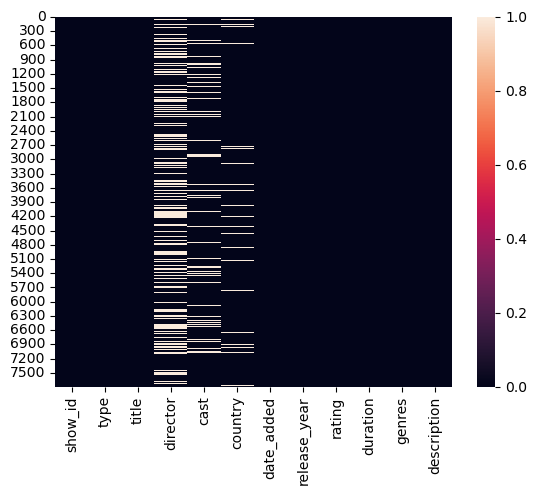

In [81]:
sns.heatmap(df.isnull())
plt.show()

### 3. Cleaning Missing Values

Missing values in the `director`, `cast`, and `country` columns are replaced with `"Unknown"` using the `fillna()` method.

- `df.copy()`: Creates a copy of the original dataset to preserve the original data.
- `fillna('Unknown')`: Replaces missing (`NaN`) values with `"Unknown"` in the specified columns.

##### Missing values in the selected columns have been handled by assigning `"Unknown"` to unavailable information. The updated DataFrame `df1` is used for further analysis.

In [149]:
df1 = df.copy()

df1['director'] = df1['director'].fillna('Unknown')
df1['cast'] = df1['cast'].fillna('Unknown')
df1['country'] = df1['country'].fillna('Unknown')

### 4. Verifying if all the missing values has been removed

In [84]:
df1 = df1.dropna()
print(df1.isnull().sum()/len(df1)*100)

show_id         0.0
type            0.0
title           0.0
director        0.0
cast            0.0
country         0.0
date_added      0.0
release_year    0.0
rating          0.0
duration        0.0
genres          0.0
description     0.0
dtype: float64


In [85]:
print("Copied Dataset: ",df1.shape)

Copied Dataset:  (7770, 12)


In [86]:
print("Original Dataset: ",df.shape)

Original Dataset:  (7787, 12)


In [150]:
print(df1.duplicated().sum())  #checking for the duplicated data items

0


In [89]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7770 entries, 0 to 7786
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       7770 non-null   object
 1   type          7770 non-null   object
 2   title         7770 non-null   object
 3   director      7770 non-null   object
 4   cast          7770 non-null   object
 5   country       7770 non-null   object
 6   date_added    7770 non-null   object
 7   release_year  7770 non-null   int64 
 8   rating        7770 non-null   object
 9   duration      7770 non-null   int64 
 10  genres        7770 non-null   object
 11  description   7770 non-null   object
dtypes: int64(2), object(10)
memory usage: 789.1+ KB


### 5. Content Type Distribution

##### To analyze the distribution of content types (Movies and TV Shows) available on Netflix. 
##### Used Bar Graph

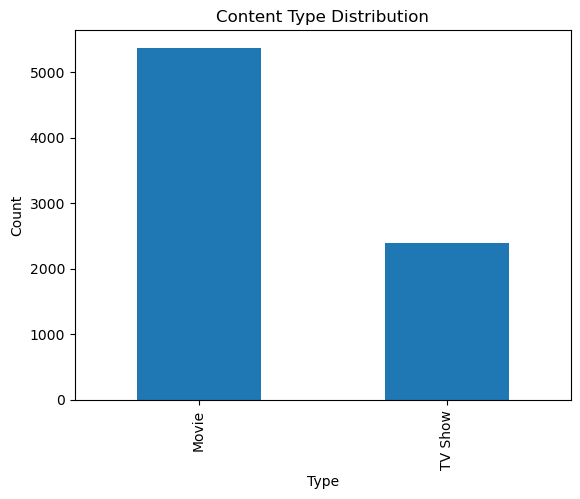

In [91]:
df1['type'].value_counts().plot.bar()
plt.title("Content Type Distribution")

plt.xlabel("Type")
plt.ylabel("Count")
plt.show()

### 6. Distribution of Content by Release Year

##### This analysis helps identify release years with fewer or more Netflix titles in the dataset. It sorts the years based on their frequency counts, not chronologically by release year.

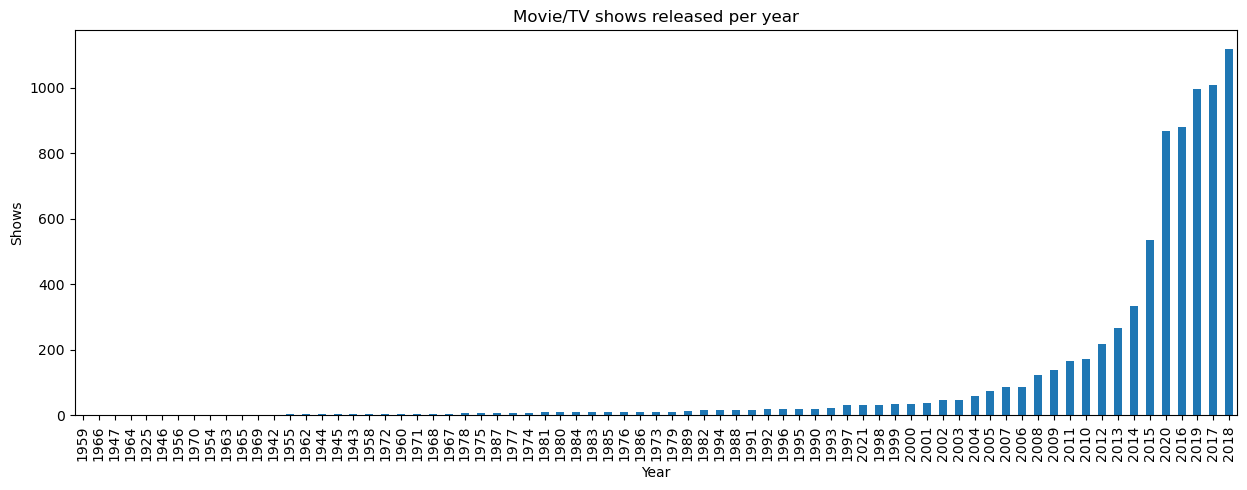

In [103]:
df1['release_year'].value_counts().sort_values().plot(
    kind="bar",
    figsize = (15,5)
)
plt.title("Movie/TV shows released per year")
plt.xlabel("Year")
plt.ylabel("Shows")
plt.show()

### 6. Top 10 Countries Producing Netflix Content

##### The bar chart highlights the 10 countries most frequently associated with Netflix content in the dataset. This helps identify the major content-producing countries represented on Netflix.


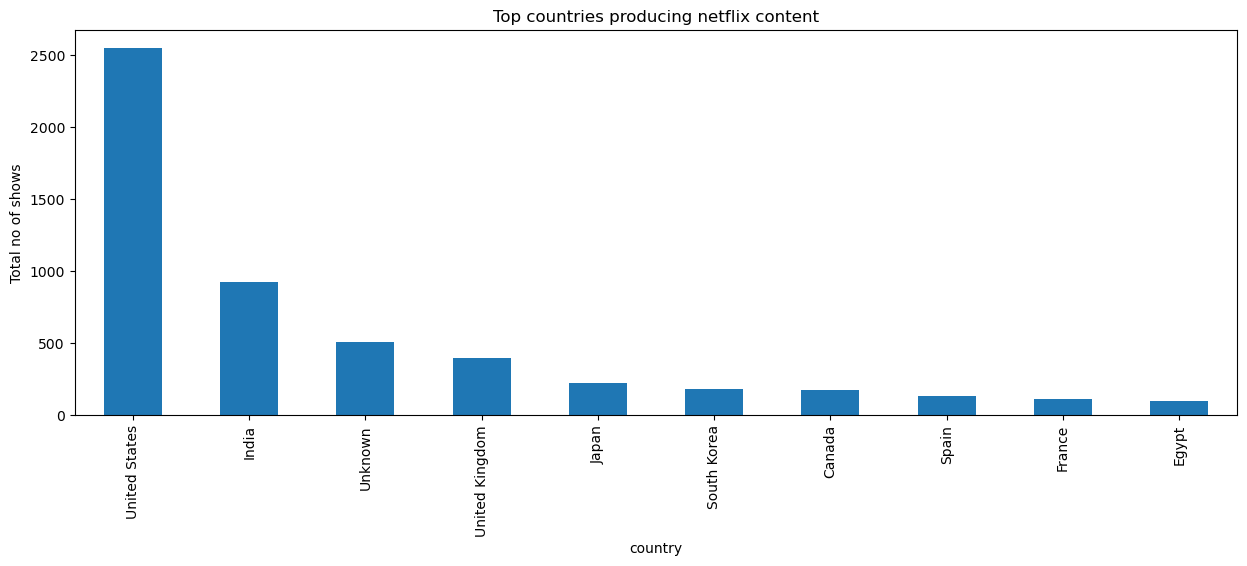

In [105]:
df1['country'].value_counts().head(10).plot(
    kind="bar",
    figsize = (15,5)
)
plt.title("Top countries producing netflix content")
plt.xlabel("country")
plt.ylabel("Total no of shows")
plt.show()

### 7. Top 10 Directors on Netflix

- `from collections import Counter` – Imports `Counter`, which counts the frequency of items.
- `df1[df1["director"] != "Unknown"]` – Excludes rows where the director is marked as `"Unknown"`.
- `director.split(",")` – Splits entries containing multiple directors into individual names.
- `dir.strip()` – Removes leading and trailing spaces from each director's name.
- `Counter(...)` – Counts the number of appearances of each director.
- `direct.most_common(10)` – Retrieves the 10 directors with the highest counts.
- `pd.Series(dict(top_dir))` – Converts the results into a Pandas Series for plotting.


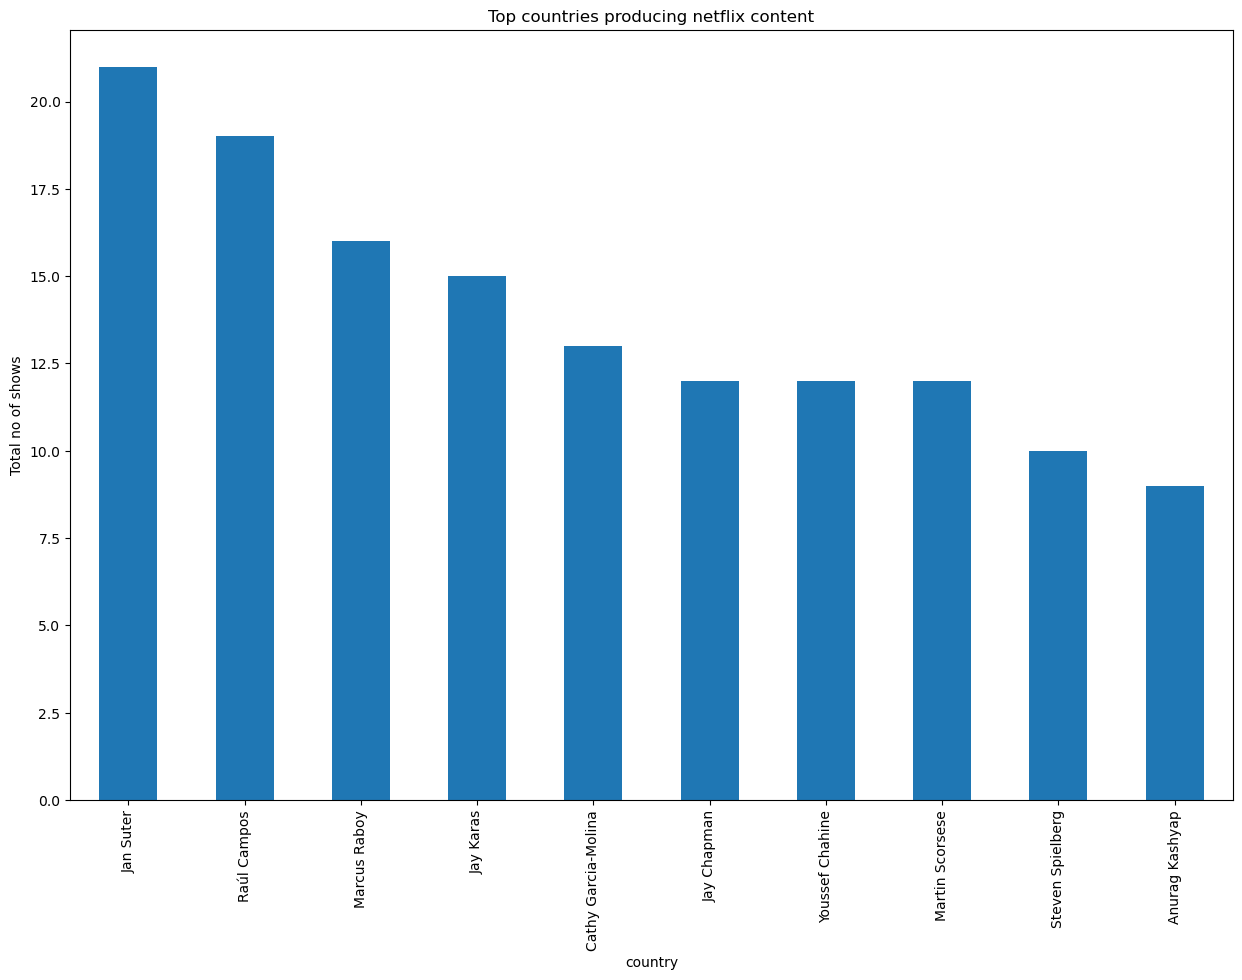

In [151]:
from collections import Counter 
# counter: counts how many each item appear in the data

direct = Counter(
    dir.strip()
    for director in df1[df1["director"]!="Unknown"]['director'].dropna()
    for dir in director.split(",")
)
top_dir = direct.most_common(10)
top_dire_df = pd.Series(dict(top_dir))
top_dire_df.plot(kind = "bar", figsize = (15,10))

plt.title("Top countries producing netflix content")
plt.xlabel("country")
plt.ylabel("Total no of shows")
plt.show()

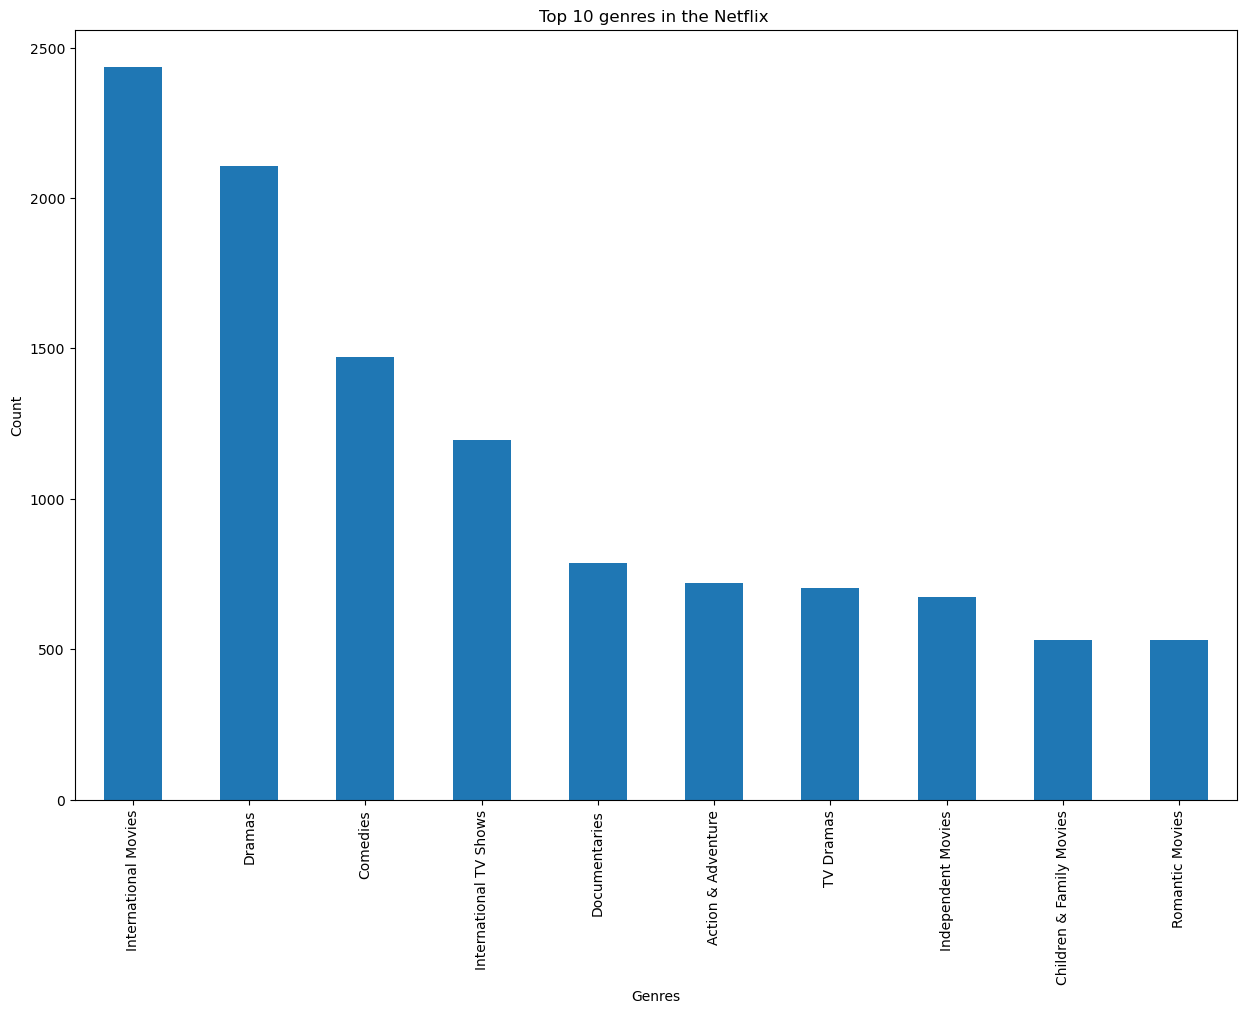

In [126]:
from collections import Counter 
# counter: counts how many each item appear in the data

genre_count = Counter(
    genre.strip()
    for genres in df1["genres"].dropna()
    for genre in genres.split(",")
)
top_genre = genre_count.most_common(10)

top_genre_df = pd.Series(dict(top_genre))
top_genre_df.plot(kind = "bar", figsize = (15,10))
plt.title("Top 10 genres in the Netflix ")
plt.xlabel("Genres")
plt.ylabel("Count")
plt.show()

In [140]:
df1['duration'].sort_values(ascending= False).head()

7741    312
6502    253
3880    237
2995    233
4567    230
Name: duration, dtype: int64

### 8. Finding the Longest Movie on Netflix



In [147]:
max_movie = df1.loc[df1["duration"].idxmax()]
print("Longest movie in netflix: ",max_movie['title'])

Longest movie in netflix:  Black Mirror: Bandersnatch


In [148]:
min_movie = df1.loc[df1["duration"].idxmin()]
print("Shortest movie in netflix: ",min_movie['title'])

Shortest movie in netflix:  Blue Planet II
